<a href="https://colab.research.google.com/github/6710110109/Screen-Time-Health-Impact-AI-Predictor/blob/main/6710110109_AI_minproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **AI-Miniproject : ระบบทำนายผลกระทบสุขภาพจากเวลาหน้าจอ**

**นายณภัทร ปานเกลี้ยง 6710110109**

ขั้นตอนที่ 1: Import ไลบรารีที่จำเป็น

In [ ]:
import warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore')

ขั้นตอนที่ 2: โหลดข้อมูล (Data Loading)

In [ ]:
from google.colab import drive

# เชื่อมต่อ Google Drive
drive.mount('/content/drive')

# อ่านไฟล์ CSV
df = pd.read_csv('/content/Indian_Kids_Screen_Time.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


ขั้นตอนที่ 3: สำรวจข้อมูลเบื้องต้น (Data Exploration & Inspection)

In [ ]:
import pandas as pd
from IPython.display import HTML, display


def print_section(title):
  display(
      HTML(
          f'<div style="background-color:#212529; color:#00E676; padding:8px'
          ' 15px; border-radius:5px; font-weight:bold; font-size:16px;'
          f' margin-top:20px; margin-bottom:10px;"> {title}</div>'
      )
  )


# 1. ดูตัวอย่างข้อมูล 5 แถวแรก
print_section('1. ตัวอย่างข้อมูล (5 แถวแรก)')
display(df.head())

# 2. ตรวจสอบ Missing Values และ Duplicates สรุปในตารางเดียว
print_section('2. สรุปข้อมูลที่ขาดหายและแถวซ้ำ (Missing & Duplicates)')
missing_df = pd.DataFrame(
    {'Missing Values': df.isnull().sum(), 'Data Type': df.dtypes}
)
display(missing_df.T)
print(f" Total Duplicate Rows: {df.duplicated().sum()} แถว")

# 3. ตรวจสอบโครงสร้างข้อมูล (Data Info) แบบจัดรูปแบบ
print_section('3. โครงสร้างข้อมูล (Data Types & Non-Null)')
info_df = pd.DataFrame({
    'Column Name': df.columns,
    'Non-Null Count': df.notnull().sum().values,
    'Data Type': df.dtypes.values,
})
display(info_df.T)

# 4. สถิติเชิงพรรณนา (Statistical Summary)
print_section('4. สถิติเชิงพรรณนา (Statistical Summary)')
display(df.describe().T.style.background_gradient(cmap='Blues'))

,Age,Gender,Avg_Daily_Screen_Time_hr,Primary_Device,Exceeded_Recommended_Limit,Educational_to_Recreational_Ratio,Health_Impacts,Urban_or_Rural
0,14,Male,3.99,Smartphone,True,0.42,"Poor Sleep, Eye Strain",Urban
1,11,Female,4.61,Laptop,True,0.30,Poor Sleep,Urban
2,18,Female,3.73,TV,True,0.32,Poor Sleep,Urban
3,15,Female,1.21,Laptop,False,0.39,NaN,Urban
4,12,Female,5.89,Smartphone,True,0.49,"Poor Sleep, Anxiety",Urban


,Age,Gender,Avg_Daily_Screen_Time_hr,Primary_Device,Exceeded_Recommended_Limit,Educational_to_Recreational_Ratio,Health_Impacts,Urban_or_Rural
Missing Values,0,0,0,0,0,0,3218,0
Data Type,int64,object,float64,object,bool,float64,object,object


 Total Duplicate Rows: 44 แถว


,0,1,2,3,4,5,6,7
Column Name,Age,Gender,Avg_Daily_Screen_Time_hr,Primary_Device,Exceeded_Recommended_Limit,Educational_to_Recreational_Ratio,Health_Impacts,Urban_or_Rural
Non-Null Count,9712,9712,9712,9712,9712,9712,6494,9712
Data Type,int64,object,float64,object,bool,float64,object,object


,count,mean,std,min,25%,50%,75%,max
Age,9712.000000,12.979201,3.162437,8.000000,10.000000,13.000000,16.000000,18.000000
Avg_Daily_Screen_Time_hr,9712.000000,4.352837,1.718232,0.000000,3.410000,4.440000,5.380000,13.890000
Educational_to_Recreational_Ratio,9712.000000,0.427226,0.073221,0.300000,0.370000,0.430000,0.480000,0.600000


ขั้นตอนที่ 4: การทำความสะอาดข้อมูล (Data Cleaning)

In [ ]:
# 1. ปรับชื่อคอลัมน์ให้อยู่ในรูปแบบตัวพิมพ์เล็กทั้งหมดเพื่อความสะดวกในการเรียกใช้
df.columns = df.columns.str.lower()

# 2. จัดการข้อมูลซ้ำ (ถ้ามี)
df = df.drop_duplicates()

# 3. จัดการข้อมูลที่ขาดหายไป (Missing Values)
# สำหรับคอลัมน์ตัวเลข: แทนที่ด้วยค่ากลาง (Median)
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# สำหรับคอลัมน์ข้อความ (Categorical): แทนที่ด้วยค่าฐานนิยม (Mode)
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

ขั้นตอนที่ 5: จัดการข้อมูล Outliers (Outlier Detection & Handling)

In [ ]:
# ใช้เทคนิค IQR Method ในการจัดการ Outliers สำหรับคอลัมน์ตัวเลข (ไม่รวม target)
features_to_check = [col for col in num_cols if col != 'health_impacts']

for col in features_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Clip ค่าให้อยู่ในช่วง Bound เพื่อไม่ให้ Outliers ส่งผลเสียต่อโมเดล
    df[col] = np.clip(df[col], lower_bound, upper_bound)

ขั้นตอนที่ 6: การแปลงข้อมูล Categorical (Feature Encoding)

In [ ]:
# ระบุคอลัมน์เชิงคุณภาพที่ต้องการแปลง
categorical_cols = ['gender', 'primary_device', 'exceeded_recommended_limit', 'urban_or_rural']

# ทำ One-Hot Encoding
encoder = OneHotEncoder(drop='first', sparse_output=False)
encoded_array = encoder.fit_transform(df[categorical_cols])

# สร้าง DataFrame สำหรับ Feature ที่ทำ Encoding แล้ว
encoded_df = pd.DataFrame(
    encoded_array,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=df.index
)

# รวม DataFrame ข้อมูลเดิม (ตัดคอลัมน์ประเภทข้อความเดิมออก) กับข้อมูลที่ Encode แล้ว
df_cleaned = pd.concat([df.drop(columns=categorical_cols), encoded_df], axis=1)

# หากมีคอลัมน์ ID หรือคอลัมน์ที่ไม่จำเป็นต่อการสร้างโมเดล สามารถ Drop ออกได้ที่นี่
if 'user_id' in df_cleaned.columns:
    df_cleaned = df_cleaned.drop(columns=['user_id'])

ขั้นตอนที่ 7: แยก Features (X) และ Target (y)

In [ ]:
# สมมติให้ 'health_impacts' หรือคอลัมน์เป้าหมายหลักเป็น Target (ปรับชื่อตามจริงได้)
target_col = 'health_impacts'

X = df_cleaned.drop(columns=[target_col])
y = df_cleaned[target_col]

ขั้นตอนที่ 8: แบ่งข้อมูลเป็น Train Set และ Test Set

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y if df_cleaned[target_col].dtype == 'object' or len(np.unique(y)) < 10 else None
)

print(f"X_train Shape: {X_train.shape}")
print(f"X_test Shape: {X_test.shape}")

X_train Shape: (7734, 9)
X_test Shape: (1934, 9)


ขั้นตอนที่ 9: สเกลข้อมูล (Feature Scaling)

In [ ]:
# ปรับสเกลข้อมูลตัวเลขให้มีมาตรฐานเดียวกัน (Mean=0, Std=1)
scaler = StandardScaler()

# Fit เฉพาะกับ Train Set แล้วค่อย Transform ทั้ง Train และ Test เพื่อป้องกัน Data Leakage
scale_cols = [col for col in X_train.select_dtypes(include=['int64', 'float64']).columns if col in num_cols]

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

# แสดงผลลัพธ์ข้อมูลที่พร้อมนำไปเข้า Machine Learning Model
display(X_train.head())

,age,avg_daily_screen_time_hr,educational_to_recreational_ratio,gender_Male,primary_device_Smartphone,primary_device_TV,primary_device_Tablet,exceeded_recommended_limit_True,urban_or_rural_Urban
322,-1.577152,-2.378451,1.679917,0.0,1.0,0.0,0.0,0.0,1.0
7107,1.264588,0.381072,0.581930,1.0,0.0,0.0,0.0,1.0,1.0
8235,-0.945654,1.788099,2.228910,1.0,1.0,0.0,0.0,1.0,1.0
1360,0.948839,-0.337802,-0.516057,1.0,0.0,0.0,0.0,1.0,0.0
1689,-0.314157,1.112235,0.444682,1.0,1.0,0.0,0.0,1.0,1.0


ขั้นตอนที่ 10: เลือกและสร้างโมเดล Machine Learning (Model Training)

In [ ]:
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ตรวจสอบประเภทของ Target เพื่อเลือกโมเดลที่เหมาะสม
is_classification = (y.dtype == 'object') or (len(np.unique(y)) < 10)

if is_classification:
    # 1. Classification Models
    models = {
        'Logistic Regression': LogisticRegression(random_state=42),
        'Decision Tree': DecisionTreeClassifier(random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
    }
else:
    # 2. Regression Models (กรณี target เป็นตัวเลขต่อเนื่อง)
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.tree import DecisionTreeRegressor

    models = {
        'Linear Regression': LinearRegression(),
        'Decision Tree': DecisionTreeRegressor(random_state=42),
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42)
    }

# เทรนโมเดลทั้งหมดและเก็บไว้ใน Dictionary
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f" {name} trained successfully.")

 Logistic Regression trained successfully.
 Decision Tree trained successfully.
 Random Forest trained successfully.


ขั้นตอนที่ 11: ประเมินประสิทธิภาพของโมเดล (Model Evaluation)

,precision,recall,f1-score,support
Anxiety,0.000,0.000,0.000,77.000
"Anxiety, Obesity Risk",0.000,0.000,0.000,14.000
Eye Strain,0.000,0.000,0.000,129.000
"Eye Strain, Anxiety",0.000,0.000,0.000,27.000
"Eye Strain, Anxiety, Obesity Risk",0.000,0.000,0.000,7.000
"Eye Strain, Obesity Risk",0.000,0.000,0.000,21.000
Obesity Risk,0.000,0.000,0.000,50.000
Poor Sleep,0.563,1.000,0.720,1089.000
"Poor Sleep, Anxiety",0.000,0.000,0.000,121.000
"Poor Sleep, Anxiety, Obesity Risk",0.000,0.000,0.000,16.000


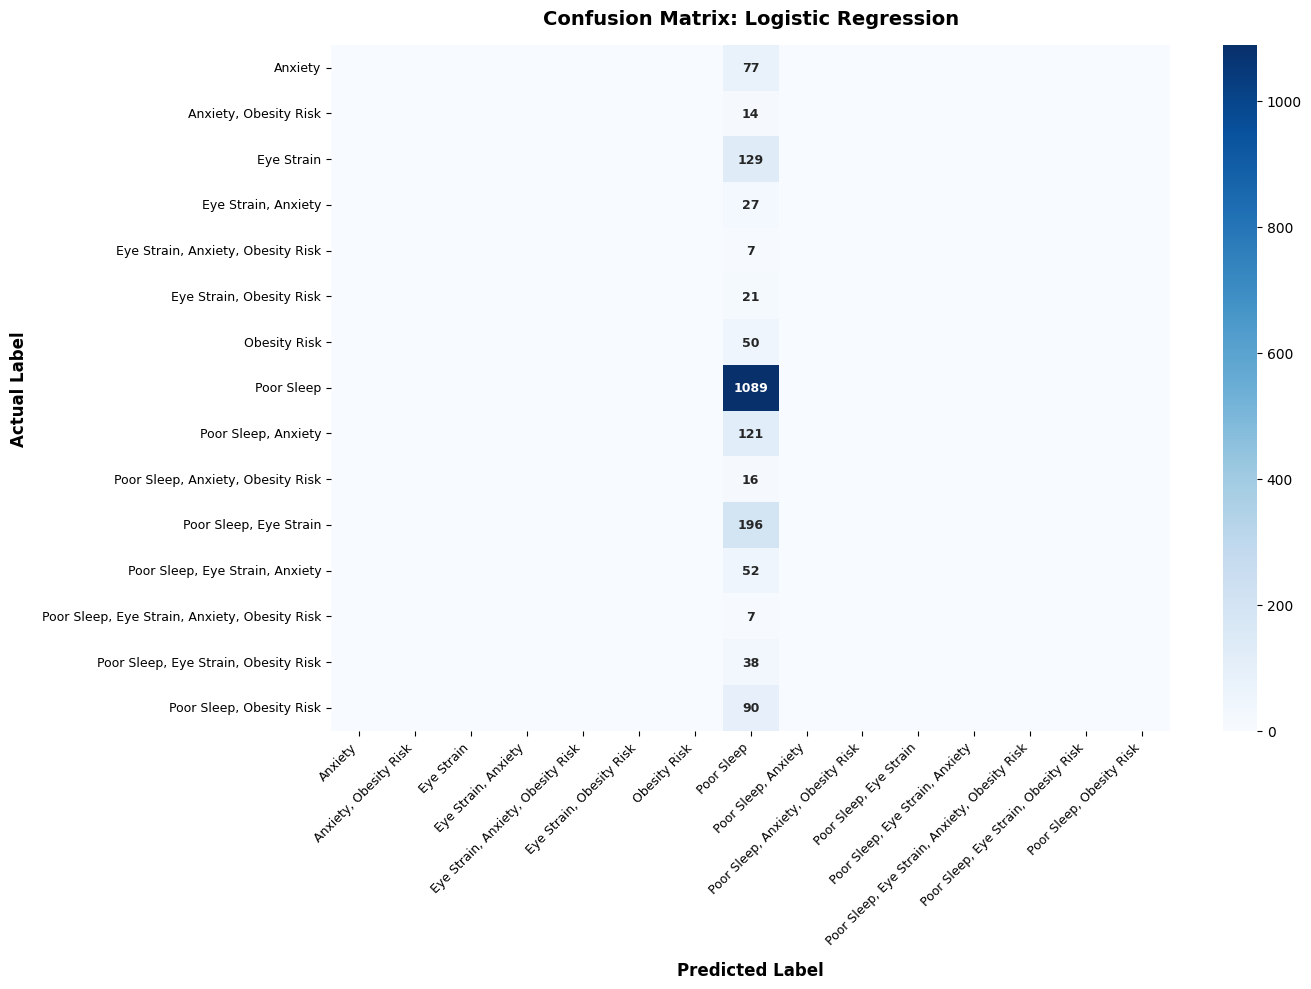

,precision,recall,f1-score,support
Anxiety,0.029,0.026,0.027,77.000
"Anxiety, Obesity Risk",0.000,0.000,0.000,14.000
Eye Strain,0.072,0.078,0.075,129.000
"Eye Strain, Anxiety",0.027,0.037,0.031,27.000
"Eye Strain, Anxiety, Obesity Risk",0.000,0.000,0.000,7.000
"Eye Strain, Obesity Risk",0.000,0.000,0.000,21.000
Obesity Risk,0.051,0.060,0.055,50.000
Poor Sleep,0.649,0.618,0.633,1089.000
"Poor Sleep, Anxiety",0.060,0.066,0.063,121.000
"Poor Sleep, Anxiety, Obesity Risk",0.000,0.000,0.000,16.000


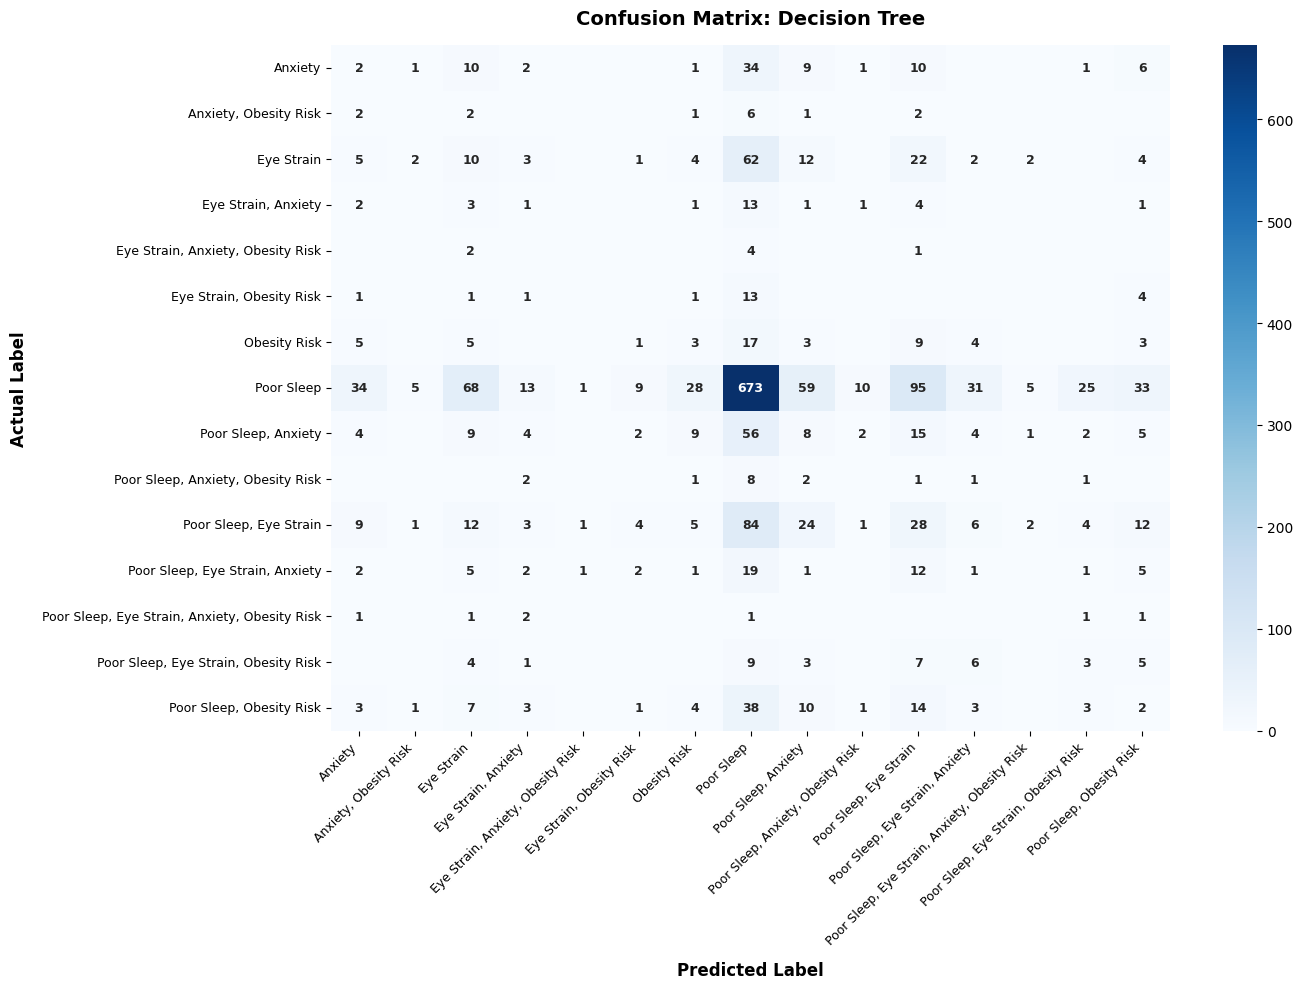

,precision,recall,f1-score,support
Anxiety,0.079,0.039,0.052,77.000
"Anxiety, Obesity Risk",0.000,0.000,0.000,14.000
Eye Strain,0.067,0.039,0.049,129.000
"Eye Strain, Anxiety",0.000,0.000,0.000,27.000
"Eye Strain, Anxiety, Obesity Risk",0.000,0.000,0.000,7.000
"Eye Strain, Obesity Risk",0.000,0.000,0.000,21.000
Obesity Risk,0.043,0.020,0.027,50.000
Poor Sleep,0.594,0.831,0.693,1089.000
"Poor Sleep, Anxiety",0.125,0.066,0.086,121.000
"Poor Sleep, Anxiety, Obesity Risk",0.000,0.000,0.000,16.000


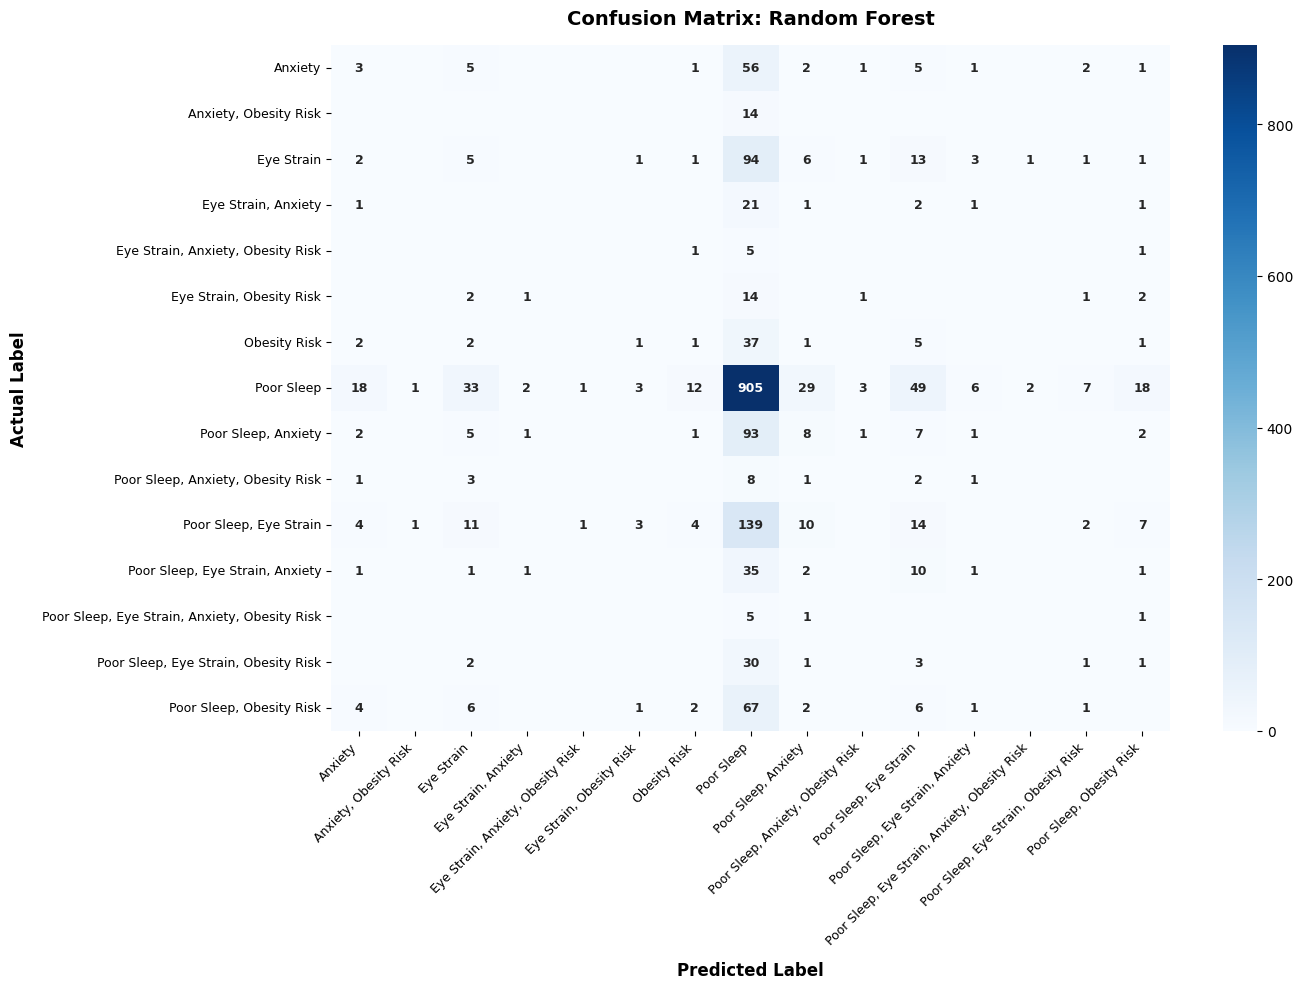

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

if is_classification:
  display(
      HTML(
          '<h2 style="color:#2b5c8f; border-bottom:2px solid'
          ' #2b5c8f;">CLASSIFICATION EVALUATION METRICS</h2>'
      )
  )

  # ดึงรายการ Class ทั้งหมด
  labels = sorted(list(set(y_test)))

  # สร้างตัวย่อชื่อคลาส เช่น "Poor Sleep, Eye Strain" -> "PS, ES" เพื่อไม่ให้แกนเบียดกัน
  short_labels = [
      ''.join([word[0] for word in item.replace(',', '').split()])
      for item in labels
  ]

  for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    display(
        HTML(
            f'<div style="background-color:#eef2f5; padding:8px 12px;'
            ' border-left:5px solid #2b5c8f; font-weight:bold;'
            f' margin-top:20px;">Model: {name} (Accuracy: {acc*100:.2f}%)</div>'
        )
    )

    # 1. Classification Report ตารางสวยงาม
    report_dict = classification_report(y_test, y_pred, output_dict=True)
    report_df = pd.DataFrame(report_dict).T
    display(
        report_df.style.format('{:.3f}').background_gradient(
            cmap='Greens', subset=['precision', 'recall', 'f1-score']
        )
    )

    # 2. Confusion Matrix ขนาดใหญ่พิเศษ
    cm = confusion_matrix(y_test, y_pred, labels=labels)

    # สร้าง Annotations ซ่อนเลข 0 เพื่อให้มองเห็นเฉพาะค่าที่มีการทำนายจริง
    annot_matrix = np.where(cm == 0, '', cm.astype(str))

    plt.figure(figsize=(14, 10))  # ขยายขนาดพื้นที่กราฟ
    sns.heatmap(
        cm,
        annot=annot_matrix,
        fmt='',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        cbar=True,
        annot_kws={'size': 9, 'weight': 'bold'},
    )

    plt.title(f'Confusion Matrix: {name}', fontsize=14, pad=15, weight='bold')
    plt.xlabel('Predicted Label', fontsize=12, fontweight='bold', labelpad=10)
    plt.ylabel('Actual Label', fontsize=12, fontweight='bold', labelpad=10)

    # จัดองศาตัวหนังสือบนแกน
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.yticks(rotation=0, fontsize=9)
    plt.tight_layout()
    plt.show()

ขั้นตอนที่ 12: ดูความสำคัญของตัวแปร (Feature Importance)

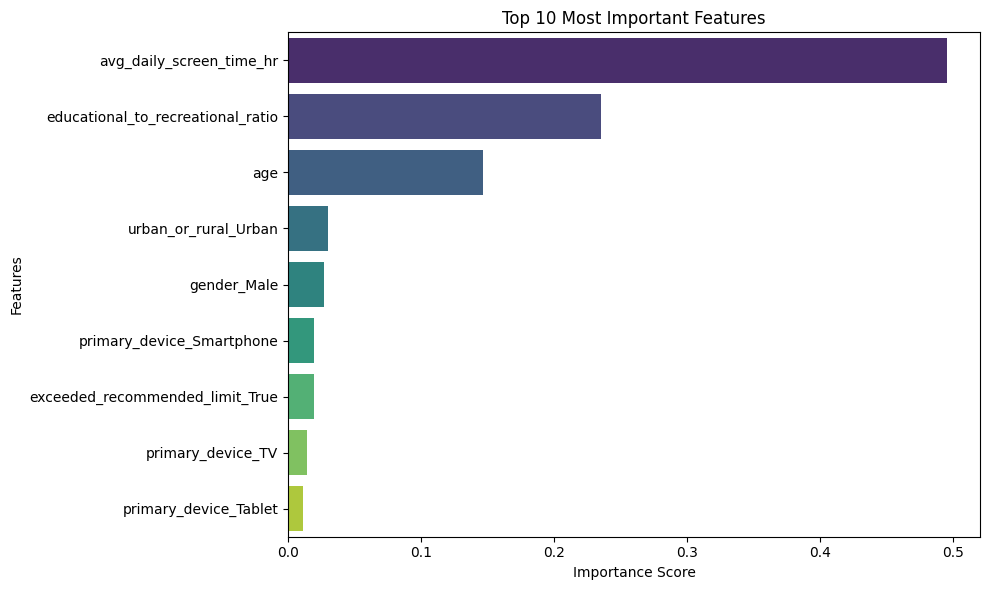

In [ ]:
best_rf_model = trained_models['Random Forest']

# ดึงค่า Feature Importance
if hasattr(best_rf_model, 'feature_importances_'):
    importances = best_rf_model.feature_importances_
    feature_names = X_train.columns

    # จัดกลุ่มใส่ DataFrame แล้วเรียงลำดับ
    feature_imp_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False)

    # วาด กราฟแสดง Feature Importance
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(10), palette='viridis')
    plt.title('Top 10 Most Important Features')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

ขั้นตอนที่ 13: บันทึกโมเดลและ Preprocessor เพื่อนำไปใช้งานจริง (Model Saving & Export)

In [ ]:
import joblib

# 1. บันทึก Objects สำหรับการเตรียมข้อมูลและสเกลข้อมูล
joblib.dump(encoder, 'onehot_encoder.pkl')
joblib.dump(scaler, 'standard_scaler.pkl')

# 2. บันทึก โมเดลที่ดีที่สุด (เช่น Random Forest)
joblib.dump(trained_models['Random Forest'], 'best_screen_time_model.pkl')

print("All preprocessing tools and models have been saved successfully!")

All preprocessing tools and models have been saved successfully!


เช็คโครงสร้าง Feature จริงเผื่อแก้

In [ ]:
print("--- 1. คอลัมน์ที่ Scaler ต้องการ ---")
print(scaler.feature_names_in_)

print("\n--- 2. คอลัมน์ที่ Encoder ต้องการ ---")
print(encoder.feature_names_in_)

print("\n--- 3. ลำดับ Feature ทั้งหมดที่ โมเดล ถูก Train มา ---")
if hasattr(model, 'feature_names_in_'):
  print(model.feature_names_in_)
else:
  print("โมเดลไม่ได้เก็บชื่อคอลัมน์ไว้ (ใช้อาร์เรย์ตามลำดับ X_train เดิม)")

--- 1. คอลัมน์ที่ Scaler ต้องการ ---
['age' 'avg_daily_screen_time_hr' 'educational_to_recreational_ratio']

--- 2. คอลัมน์ที่ Encoder ต้องการ ---
['gender' 'primary_device' 'exceeded_recommended_limit' 'urban_or_rural']

--- 3. ลำดับ Feature ทั้งหมดที่ โมเดล ถูก Train มา ---
['age' 'avg_daily_screen_time_hr' 'educational_to_recreational_ratio'
 'gender_Male' 'primary_device_Smartphone' 'primary_device_TV'
 'primary_device_Tablet' 'exceeded_recommended_limit_True'
 'urban_or_rural_Urban']


ใช้ ipywidgets (สร้าง UI ง่ายๆ ใน Colab)

In [ ]:
# ==============================================================================
# 📦 STEP 1: IMPORT LIBRARIES & LOAD DATASET
# ==============================================================================
import joblib
from IPython.display import HTML, display
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# โหลดไฟล์ Dataset
df_raw = pd.read_csv('/content/Indian_Kids_Screen_Time.csv')
df_raw.columns = df_raw.columns.str.lower()

# ==============================================================================
# 🧹 STEP 2: DATA PREPROCESSING & TARGET MULTI-LABEL TRANSFORMATION
# ==============================================================================
# 1. สร้าง Features ทางเลือกสำหรับโควต้า
# (คำนวณ limit ตามเกณฑ์อายุ: <= 5 ปี = 1.0 ชม., > 5 ปี = 2.0 ชม.)
df_raw['exceeded_recommended_limit'] = df_raw.apply(
    lambda r: r['avg_daily_screen_time_hr'] > (1.0 if r['age'] <= 5 else 2.0),
    axis=1,
)

# 2. แตก Target 15 คลาสเดิม ออกเป็น 4 คอลัมน์ Binary (0 หรือ 1) แบบ Multi-label
target_cols = ['Poor Sleep', 'Eye Strain', 'Anxiety', 'Obesity Risk']
for col in target_cols:
  df_raw[col] = df_raw['health_impacts'].apply(
      lambda x: 1 if col in str(x) else 0
  )

y_multi = df_raw[target_cols]

# 3. กำหนดตัวแปรต้น (Numerical & Categorical Features)
num_cols = [
    'age',
    'avg_daily_screen_time_hr',
    'educational_to_recreational_ratio',
]
cat_cols = [
    'gender',
    'primary_device',
    'exceeded_recommended_limit',
    'urban_or_rural',
]

# 4. Scale & Encode ข้อมูล
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(df_raw[num_cols])

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_cat_encoded = encoder.fit_transform(df_raw[cat_cols])

X_features = np.hstack([X_num_scaled, X_cat_encoded])

# 5. แบ่ง Train / Test Set
X_train, X_test, y_train_multi, y_test_multi = train_test_split(
    X_features, y_multi, test_size=0.2, random_state=42
)

# ======================================================================ระดับความเสี่ยงรายอาการ (Risk Probability)========
# 🤖 STEP 3: TRAIN MULTIOUTPUT RANDOM FOREST & EVALUATE
# ==============================================================================
base_rf = RandomForestClassifier(
    n_estimators=200, max_depth=12, class_weight='balanced', random_state=42
)
multi_model = MultiOutputClassifier(base_rf)
multi_model.fit(X_train, y_train_multi)

# ประเมินผล Accuracy แยกรายอาการ
y_pred = multi_model.predict(X_test)

print(
    '========================================================================'
)
print('🏆 ACCURACY SEPARATED BY HEALTH IMPACT (MultiOutput Model)')
print(
    '========================================================================'
)
for i, col in enumerate(target_cols):
  acc = accuracy_score(y_test_multi.iloc[:, i], y_pred[:, i])
  print(f'🎯 {col:15s} Accuracy: {acc*100:.2f}%')
print(
    '========================================================================\n'
)

# บันทึกไฟล์ Pipeline และ Model
joblib.dump(multi_model, 'best_multioutput_model.pkl')
joblib.dump(scaler, 'standard_scaler.pkl')
joblib.dump(encoder, 'onehot_encoder.pkl')


# ==============================================================================
# 📱 STEP 4: INTERACTIVE UI (DASHBOARD WITH IPYWIDGETS)
# ==============================================================================
import ipywidgets as widgets

# โหลดไฟล์เพื่อนำมารันบน UI
model = joblib.load('best_multioutput_model.pkl')
scaler = joblib.load('standard_scaler.pkl')
encoder = joblib.load('onehot_encoder.pkl')

header = widgets.HTML("""
<div style="background-color: #1e1e2e; color: #ffffff; padding: 16px; border-radius: 10px; margin-bottom: 15px; text-align: center; box-shadow: 0 4px 6px rgba(0,0,0,0.15);">
    <h2 style="margin: 0; font-family: 'Kanit', sans-serif; color: #a6e3a1;">📱 ระบบประเมินความเสี่ยงสุขภาพจากเวลาหน้าจอ</h2>
    <p style="margin: 5px 0 0 0; color: #bac2de; font-size: 14px;">วิเคราะห์ความเสี่ยงแยกรายด้านด้วย MultiOutput Random Forest Model</p>
</div>
""")

style = {'description_width': '180px'}
layout = widgets.Layout(width='450px', margin='4px 0px')

age_widget = widgets.IntSlider(
    value=18,
    min=2,
    max=18,
    description='อายุ (ปี):',
    style=style,
    layout=layout,
)
screen_time_widget = widgets.FloatSlider(
    value=3.5,
    min=0.5,
    max=12.0,
    step=0.5,
    description='เวลารวมหน้าจอ (ชม./วัน):',
    style=style,
    layout=layout,
)
edu_ratio_widget = widgets.FloatSlider(
    value=0.5,
    min=0.0,
    max=2.0,
    step=0.1,
    description='สัดส่วนเรียน/เล่น:',
    style=style,
    layout=layout,
)

gender_widget = widgets.Dropdown(
    options=['Male', 'Female'],
    value='Male',
    description='เพศ:',
    style=style,
    layout=layout,
)
device_widget = widgets.Dropdown(
    options=['Smartphone', 'Tablet', 'TV', 'Laptop'],
    value='Laptop',
    description='อุปกรณ์หลัก:',
    style=style,
    layout=layout,
)
urban_widget = widgets.Dropdown(
    options=['Urban', 'Rural'],
    value='Rural',
    description='สภาพแวดล้อมที่อยู่อาศัย:',
    style=style,
    layout=layout,
)

button = widgets.Button(
    description='🔮 เริ่มทำนายผลสุขภาพ',
    button_style='success',
    icon='check',
    layout=widgets.Layout(width='450px', height='45px', margin='15px 0px'),
)
output = widgets.Output()


def on_button_clicked(b):
  with output:
    output.clear_output()

    # 1. ดึงค่าจาก UI
    age = age_widget.value
    screen_time = screen_time_widget.value
    edu_ratio = edu_ratio_widget.value
    gender = gender_widget.value
    device = device_widget.value
    urban = urban_widget.value

    # 2. คำนวณโควต้า
    limit_hours = 1.0 if age <= 5 else 2.0
    is_exceeded = screen_time > limit_hours

    sample_cat = encoder.categories_[2][0]
    if isinstance(sample_cat, (bool, np.bool_)):
      limit_val = is_exceeded
    elif isinstance(sample_cat, (int, np.integer)):
      limit_val = 1 if is_exceeded else 0
    else:
      limit_val = 'Yes' if is_exceeded else 'No'

    # 3. แปลงค่า Features ให้ตรงตามชื่อคอลัมน์ที่โมเดลต้องการ
    num_df = pd.DataFrame([{
        'age': age,
        'avg_daily_screen_time_hr': screen_time,
        'educational_to_recreational_ratio': edu_ratio,
    }])[scaler.feature_names_in_]
    scaled_num = scaler.transform(num_df)

    cat_df = pd.DataFrame([{
        'gender': gender,
        'primary_device': device,
        'exceeded_recommended_limit': limit_val,
        'urban_or_rural': urban,
    }])[encoder.feature_names_in_]
    encoded_cat = encoder.transform(cat_df)

    input_data = np.hstack([scaled_num, encoded_cat])

    # 4. ทำนายผล 4 อาการแยกกัน + คำนวณ Probability ของแต่ละโมเดลย่อย
    predictions = model.predict(input_data)[0]
    prob_list = [
        est.predict_proba(input_data)[0][1] for est in model.estimators_
    ]

    # 5. สร้าง HTML Dashboard สวยงาม
    status_badge = (
        '<span style="background-color: #f38ba8; color: #11111b; padding: 3px'
        ' 8px; border-radius: 5px; font-weight: bold;">เกินโควต้า ⚠️</span>'
        if is_exceeded
        else '<span style="background-color: #a6e3a1; color: #11111b; padding:'
        ' 3px 8px; border-radius: 5px; font-weight: bold;">ไม่เกินโควต้า'
        ' ✅</span>'
    )

    impact_rows_html = ''
    detected_impacts = []

    for col_name, is_present, prob in zip(
        target_cols, predictions, prob_list
    ):
      percentage = prob * 100
      if is_present == 1:
        detected_impacts.append(col_name)
        bar_color = '#f38ba8'  # สีแดง
        status_txt = 'มีความเสี่ยง ⚠️'
      else:
        bar_color = '#a6e3a1'  # สีเขียว
        status_txt = 'ปกติ ✅'

      impact_rows_html += f"""
            <div style="margin-bottom: 10px; background-color: #181825; padding: 8px 12px; border-radius: 6px;">
                <div style="display: flex; justify-content: space-between; font-size: 13px; margin-bottom: 4px;">
                    <span style="font-weight: bold; color: #cdd6f4;">• {col_name}</span>
                    <span style="font-weight: bold; color: {bar_color};">{status_txt} ({percentage:.1f}%)</span>
                </div>
                <div style="background-color: #313244; height: 8px; border-radius: 4px; overflow: hidden;">
                    <div style="background-color: {bar_color}; width: {percentage}%; height: 100%;"></div>
                </div>
            </div>
            """

    summary_impact_text = (
        ', '.join(detected_impacts)
        if detected_impacts
        else 'ไม่พบความเสี่ยงชัดเจน (ปกติทุกด้าน)'
    )

    result_html = f"""
        <div style="background-color: #1e1e2e; color: #cdd6f4; border: 1px solid #45475a; border-radius: 10px; padding: 20px; font-family: sans-serif; max-width: 450px; box-shadow: 0 4px 6px rgba(0,0,0,0.2);">
            <h3 style="margin-top: 0; color: #cba6f7; border-bottom: 1px solid #45475a; padding-bottom: 8px;">📊 สรุปผลการประเมินสุขภาพ</h3>

            <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px; background-color: #181825; padding: 12px; border-radius: 8px; margin-bottom: 15px;">
                <div>
                    <div style="font-size: 12px; color: #a6adc8;">โควต้าที่แนะนำ</div>
                    <div style="font-weight: bold; font-size: 15px;">{limit_hours} ชม./วัน</div>
                </div>
                <div>
                    <div style="font-size: 12px; color: #a6adc8;">สถานะการใช้งาน</div>
                    <div style="margin-top: 2px;">{status_badge}</div>
                </div>
            </div>

            <div style="background-color: #313244; border-left: 5px solid #f9e2af; padding: 12px; border-radius: 4px; margin-bottom: 15px;">
                <div style="font-size: 12px; color: #bac2de;">🎯 อาการที่พบความเสี่ยง:</div>
                <div style="font-size: 16px; font-weight: bold; color: #f9e2af; margin-top: 2px;">{summary_impact_text}</div>
            </div>

            <h4 style="margin-bottom: 10px; color: #89b4fa;">📈 ระดับความเสี่ยงรายอาการ (Risk Probability)</h4>
            {impact_rows_html}
        </div>
        """

    display(HTML(result_html))


button.on_click(on_button_clicked)

# แสดงผล UI
display(
    header,
    age_widget,
    screen_time_widget,
    edu_ratio_widget,
    gender_widget,
    device_widget,
    urban_widget,
    button,
    output,
)